# Notebook 05: Dataset-Level Segmentation Analysis

## Objective

This notebook investigates the distribution and variability of
brain tumour segmentation regions across multiple patients
from the BraTS 2024 dataset.

Unlike the previous notebook, which focused on visualizing
segmentation masks from a single patient, this notebook
performs quantitative analysis across multiple patients.

## Research Objectives

1. Investigate the distribution of individual segmentation labels.
2. Calculate ET, TC and WT volumes for each patient.
3. Examine inter-patient tumour-volume variability.
4. Visualize tumour-region distributions.
5. Identify statistical patterns and potential dataset-level observations.

## Segmentation Labels

| Label | Region |
|---|---|
| 0 | Background |
| 1 | NETC |
| 2 | SNFH |
| 3 | ET |
| 4 | RC |

Derived regions:

- ET = {3}
- TC = {1, 3}
- WT = {1, 2, 3}

RC will be analysed separately.

## Dataset

BraTS 2024 Glioma Dataset

Initial analysis: 5–10 patients.

In [1]:
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)



In [2]:
# Dataset root directory
DATASET_ROOT = Path(
    "/kaggle/input/datasets/i212385nomanarif/2024-brats-glioma"
)

# Number of patients to initially analyse
NUM_PATIENTS = 10

# Segmentation label mapping
LABEL_MAP = {
    0: "Background",
    1: "NETC",
    2: "SNFH",
    3: "ET",
    4: "RC"
}

# Derived tumour regions
REGION_LABELS = {
    "ET": [3],
    "TC": [1, 3],
    "WT": [1, 2, 3]
}

print("Dataset exists:", DATASET_ROOT.exists())
print("Dataset location:", DATASET_ROOT)

Dataset exists: True
Dataset location: /kaggle/input/datasets/i212385nomanarif/2024-brats-glioma


In [3]:
# Find all patient directories
patient_dirs = sorted([
    path for path in DATASET_ROOT.iterdir()
    if path.is_dir() and path.name.startswith("BraTS")
])

print("Total patient directories:", len(patient_dirs))

selected_patients = patient_dirs[:NUM_PATIENTS]

print("\nSelected patients:")

for patient in selected_patients:
    print(patient.name)

Total patient directories: 700

Selected patients:
BraTS-GLI-00005-100
BraTS-GLI-00005-101
BraTS-GLI-00006-100
BraTS-GLI-00006-101
BraTS-GLI-00008-100
BraTS-GLI-00008-101
BraTS-GLI-00008-102
BraTS-GLI-00008-103
BraTS-GLI-00009-100
BraTS-GLI-00009-101


In [4]:
# Inspect files belonging to the first patient
sample_patient = selected_patients[0]

print("Patient:", sample_patient.name)
print("\nFiles:")

for file in sorted(sample_patient.iterdir()):
    print(file.name)

Patient: BraTS-GLI-00005-100

Files:
BraTS-GLI-00005-100-seg.nii
BraTS-GLI-00005-100-t1c.nii
BraTS-GLI-00005-100-t1n.nii
BraTS-GLI-00005-100-t2f.nii
BraTS-GLI-00005-100-t2w.nii


In [5]:
# Discover segmentation files for selected patients

segmentation_files = {}

for patient_dir in selected_patients:

    # Find NIfTI segmentation files
    seg_files = list(patient_dir.glob("*seg*.nii*"))

    if len(seg_files) == 0:
        print(f"Warning: No segmentation found for {patient_dir.name}")
        continue

    segmentation_files[patient_dir.name] = seg_files[0]

print("Patients with segmentation files:",
      len(segmentation_files))

for patient, filepath in segmentation_files.items():
    print(patient, "->", filepath.name)

Patients with segmentation files: 10
BraTS-GLI-00005-100 -> BraTS-GLI-00005-100-seg.nii
BraTS-GLI-00005-101 -> BraTS-GLI-00005-101-seg.nii
BraTS-GLI-00006-100 -> BraTS-GLI-00006-100-seg.nii
BraTS-GLI-00006-101 -> BraTS-GLI-00006-101-seg.nii
BraTS-GLI-00008-100 -> BraTS-GLI-00008-100-seg.nii
BraTS-GLI-00008-101 -> BraTS-GLI-00008-101-seg.nii
BraTS-GLI-00008-102 -> BraTS-GLI-00008-102-seg.nii
BraTS-GLI-00008-103 -> BraTS-GLI-00008-103-seg.nii
BraTS-GLI-00009-100 -> BraTS-GLI-00009-100-seg.nii
BraTS-GLI-00009-101 -> BraTS-GLI-00009-101-seg.nii


In [6]:
# Load the first patient's segmentation
sample_seg_path = segmentation_files[selected_patients[0].name]

sample_seg = nib.load(sample_seg_path)

# Extract segmentation data
sample_seg_data = sample_seg.get_fdata()

# Inspect metadata
print("Segmentation shape:", sample_seg.shape)
print("Data type:", sample_seg.get_data_dtype())
print("Voxel spacing (mm):", sample_seg.header.get_zooms()[:3])
print("Affine matrix:\n", sample_seg.affine)

# Identify unique segmentation labels
print("\nUnique labels:", np.unique(sample_seg_data))

Segmentation shape: (182, 218, 182)
Data type: float32
Voxel spacing (mm): (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Affine matrix:
 [[  -1.   -0.    0.   90.]
 [  -0.    1.   -0. -126.]
 [   0.    0.    1.  -72.]
 [   0.    0.    0.    1.]]

Unique labels: [0. 2. 4.]


In [7]:
def calculate_region_volumes(segmentation, voxel_spacing):

    # Physical volume of one voxel in mm³
    voxel_volume = np.prod(voxel_spacing)

    # Count individual segmentation labels
    label_counts = {
        label: np.count_nonzero(segmentation == label)
        for label in LABEL_MAP
        if label != 0
    }

    # Calculate derived tumour regions
    region_counts = {
        region: np.count_nonzero(
            np.isin(segmentation, labels)
        )
        for region, labels in REGION_LABELS.items()
    }

    # Calculate physical volumes
    region_volumes = {
        region: count * voxel_volume
        for region, count in region_counts.items()
    }

    # Convert mm³ to cm³
    region_volumes_cm3 = {
        region: volume / 1000
        for region, volume in region_volumes.items()
    }

    return {
        "label_counts": label_counts,
        "region_counts": region_counts,
        "region_volumes_mm3": region_volumes,
        "region_volumes_cm3": region_volumes_cm3
    }


# Test on the first patient
voxel_spacing = sample_seg.header.get_zooms()[:3]

sample_results = calculate_region_volumes(
    sample_seg_data,
    voxel_spacing
)

print("Voxel spacing:", voxel_spacing)
print("\nTumour region statistics:")

for region, volume in sample_results["region_volumes_cm3"].items():
    print(f"{region}: {volume:.3f} cm³")

Voxel spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))

Tumour region statistics:
ET: 0.000 cm³
TC: 0.000 cm³
WT: 22.960 cm³


In [8]:
# Print the voxel count for each segmentation label
print("Individual label distribution:")

for label, count in sample_results["label_counts"].items():
    print(f"{LABEL_MAP[label]} (Label {label}): {count:,} voxels")

# Verify the derived region volumes
print("\nDerived region volumes:")

for region, volume in sample_results["region_volumes_cm3"].items():
    print(f"{region}: {volume:.3f} cm³")

# Check the expected nesting relationship
et = sample_results["region_volumes_cm3"]["ET"]
tc = sample_results["region_volumes_cm3"]["TC"]
wt = sample_results["region_volumes_cm3"]["WT"]

print("\nRegion nesting check:")
print("ET <= TC:", et <= tc)
print("TC <= WT:", tc <= wt)

Individual label distribution:
NETC (Label 1): 0 voxels
SNFH (Label 2): 22,960 voxels
ET (Label 3): 0 voxels
RC (Label 4): 4,246 voxels

Derived region volumes:
ET: 0.000 cm³
TC: 0.000 cm³
WT: 22.960 cm³

Region nesting check:
ET <= TC: True
TC <= WT: True


In [9]:
# Store the statistics of all patients
patient_records = []

# Process each selected patient
for patient_dir in selected_patients:

    patient_id = patient_dir.name

    # Locate the patient's segmentation file
    seg_path = segmentation_files.get(patient_id)

    if seg_path is None:
        print(f"Warning: Segmentation missing for {patient_id}")
        continue

    # Load the segmentation
    seg_img = nib.load(seg_path)
    seg_data = np.asanyarray(seg_img.dataobj)

    # Extract voxel spacing
    voxel_spacing = seg_img.header.get_zooms()[:3]

    # Identify labels present in the segmentation
    unique_labels = np.unique(seg_data)

    # Check for unexpected labels
    unknown_labels = set(unique_labels) - set(LABEL_MAP.keys())

    if unknown_labels:
        raise ValueError(
            f"Unexpected labels in {patient_id}: {unknown_labels}"
        )

    # Calculate segmentation statistics
    results = calculate_region_volumes(
        seg_data,
        voxel_spacing
    )

    # Create a record for this patient
    record = {
        "patient_id": patient_id,
        "voxel_spacing": tuple(voxel_spacing),
        "voxel_volume_mm3": np.prod(voxel_spacing)
    }

    # Add individual label voxel counts
    for label, label_name in LABEL_MAP.items():

        if label == 0:
            continue

        record[f"{label_name}_voxels"] = (
            results["label_counts"].get(label, 0)
        )

    # Add derived region voxel counts and physical volumes
    for region in REGION_LABELS:

        record[f"{region}_voxels"] = (
            results["region_counts"][region]
        )

        record[f"{region}_cm3"] = (
            results["region_volumes_cm3"][region]
        )

    # Validate the region nesting relationship
    et = record["ET_cm3"]
    tc = record["TC_cm3"]
    wt = record["WT_cm3"]

    record["nesting_valid"] = (et <= tc <= wt)

    if not record["nesting_valid"]:
        print(f"Warning: Region nesting failed for {patient_id}")

    # Save the patient's record
    patient_records.append(record)


print(f"Successfully processed {len(patient_records)} patients.")

Successfully processed 10 patients.


In [10]:
dataset_df = pd.DataFrame(patient_records)

display(dataset_df)

print("Dataset shape:", dataset_df.shape)

# Inspect column data types
print("\nColumn information:")
dataset_df.info()

,patient_id,voxel_spacing,voxel_volume_mm3,NETC_voxels,SNFH_voxels,ET_voxels,RC_voxels,ET_cm3,TC_voxels,TC_cm3,WT_voxels,WT_cm3,nesting_valid
0,BraTS-GLI-00005-100,"(1.0, 1.0, 1.0)",1.000,0,22960,0,4246,0.000,0,0.000,22960,22.960,True
1,BraTS-GLI-00005-101,"(1.0, 1.0, 1.0)",1.000,0,23658,0,3641,0.000,0,0.000,23658,23.658,True
2,BraTS-GLI-00006-100,"(1.0, 1.0, 1.0)",1.000,0,17907,0,22074,0.000,0,0.000,17907,17.907,True
3,BraTS-GLI-00006-101,"(1.0, 1.0, 1.0)",1.000,0,18747,0,18491,0.000,0,0.000,18747,18.747,True
4,BraTS-GLI-00008-100,"(1.0, 1.0, 1.0)",1.000,0,6976,135,1816,0.135,135,0.135,7111,7.111,True
5,BraTS-GLI-00008-101,"(1.0, 1.0, 1.0)",1.000,0,7771,66,1903,0.066,66,0.066,7837,7.837,True
6,BraTS-GLI-00008-102,"(1.0, 1.0, 1.0)",1.000,0,14891,537,1891,0.537,537,0.537,15428,15.428,True
7,BraTS-GLI-00008-103,"(1.0, 1.0, 1.0)",1.000,0,9588,178,1756,0.178,178,0.178,9766,9.766,True
8,BraTS-GLI-00009-100,"(1.0, 1.0, 1.0)",1.000,177,73175,6311,2984,6.311,6488,6.488,79663,79.663,True
9,BraTS-GLI-00009-101,"(1.0, 1.0, 1.0)",1.000,559,81545,11334,727,11.334,11893,11.893,93438,93.438,True


Dataset shape: (10, 13)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   patient_id        10 non-null     object 
 1   voxel_spacing     10 non-null     object 
 2   voxel_volume_mm3  10 non-null     float32
 3   NETC_voxels       10 non-null     int64  
 4   SNFH_voxels       10 non-null     int64  
 5   ET_voxels         10 non-null     int64  
 6   RC_voxels         10 non-null     int64  
 7   ET_cm3            10 non-null     float32
 8   TC_voxels         10 non-null     int64  
 9   TC_cm3            10 non-null     float32
 10  WT_voxels         10 non-null     int64  
 11  WT_cm3            10 non-null     float32
 12  nesting_valid     10 non-null     bool   
dtypes: bool(1), float32(4), int64(6), object(2)
memory usage: 942.0+ bytes


In [11]:
volume_columns = ["ET_cm3", "TC_cm3", "WT_cm3"]

# Calculate descriptive statistics
volume_statistics = dataset_df[volume_columns].describe().T

volume_statistics["median"] = dataset_df[volume_columns].median()

display(volume_statistics)

,count,mean,std,min,25%,50%,75%,max,median
ET_cm3,10.000,1.856,3.861,0.000,0.000,0.101,0.447,11.334,0.101
TC_cm3,10.000,1.930,4.037,0.000,0.000,0.101,0.447,11.893,0.101
WT_cm3,10.000,29.652,30.712,7.111,11.181,18.327,23.484,93.438,18.327


# Histogram Analysis(10 patients)

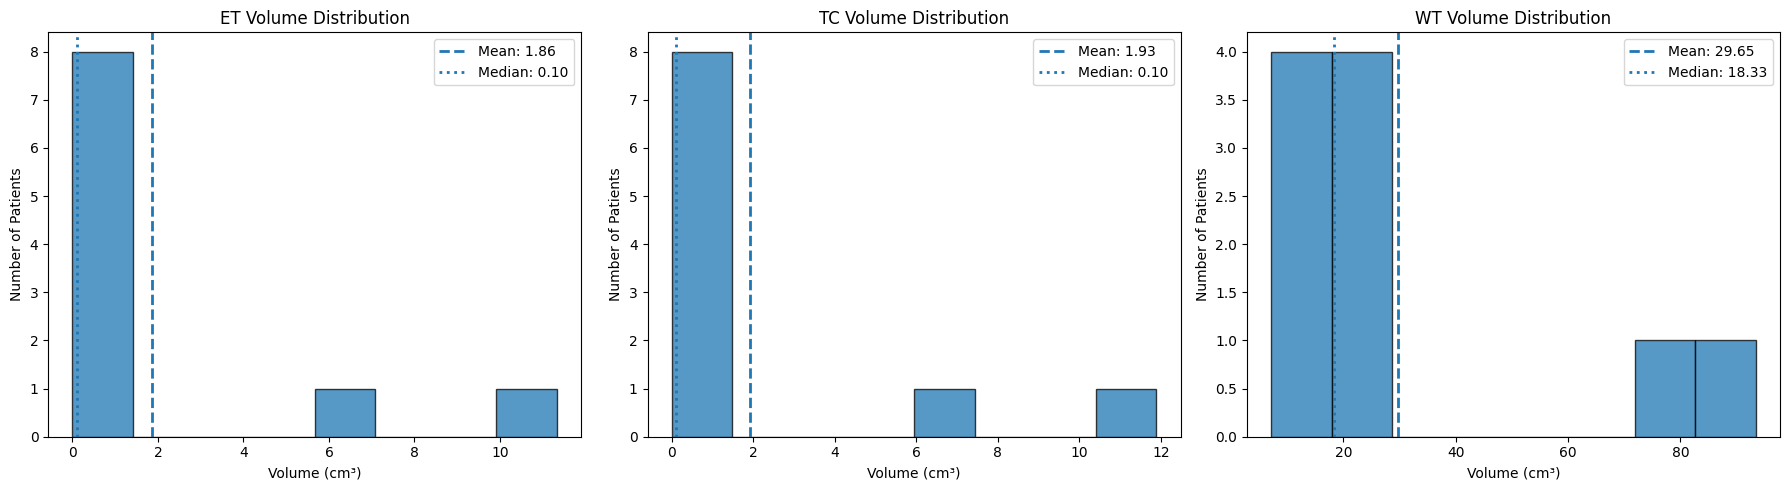

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

regions = ["ET_cm3", "TC_cm3", "WT_cm3"]

for ax, region in zip(axes, regions):

    # Extract the volume measurements
    volumes = dataset_df[region]

    # Plot the histogram
    ax.hist(
        volumes,
        bins=8,
        edgecolor="black",
        alpha=0.75
    )

    # Calculate mean and median
    mean_volume = volumes.mean()
    median_volume = volumes.median()

    # Mark the mean and median
    ax.axvline(
        mean_volume,
        linestyle="--",
        linewidth=2,
        label=f"Mean: {mean_volume:.2f}"
    )

    ax.axvline(
        median_volume,
        linestyle=":",
        linewidth=2,
        label=f"Median: {median_volume:.2f}"
    )

    # Add labels and title
    ax.set_title(f"{region.replace('_cm3', '')} Volume Distribution")
    ax.set_xlabel("Volume (cm³)")
    ax.set_ylabel("Number of Patients")
    ax.legend()

# Improve spacing between plots
plt.tight_layout()
plt.show()

# Boxplot Analysis

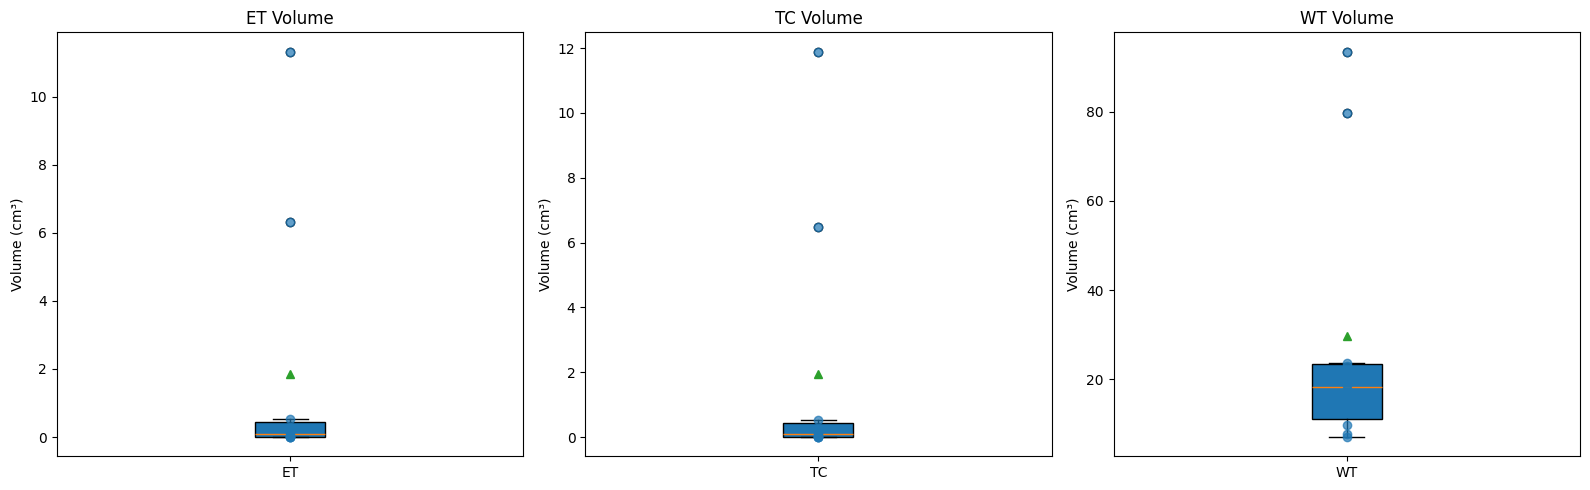

In [13]:
# Create a figure for comparing tumour-region volumes
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

regions = ["ET_cm3", "TC_cm3", "WT_cm3"]

for ax, region in zip(axes, regions):

    # Extract patient-level volumes
    volumes = dataset_df[region]

    # Generate the boxplot
    ax.boxplot(
        volumes,
        patch_artist=True,
        showmeans=True
    )

    # Add individual patient observations
    ax.scatter(
        np.ones(len(volumes)),
        volumes,
        alpha=0.7,
        zorder=3
    )

    ax.set_title(f"{region.replace('_cm3', '')} Volume")
    ax.set_ylabel("Volume (cm³)")
    ax.set_xticks([1])
    ax.set_xticklabels([region.replace("_cm3", "")])

# Improve layout
plt.tight_layout()
plt.show()

In [14]:
# Define the tumour regions to analyse
regions = ["ET_cm3", "TC_cm3", "WT_cm3"]

# Store outlier analysis results
outlier_results = []

for region in regions:

    # Extract the volume measurements
    volumes = dataset_df[region]

    # Calculate the first and third quartiles
    q1 = volumes.quantile(0.25)
    q3 = volumes.quantile(0.75)

    # Calculate the interquartile range
    iqr = q3 - q1

    # Calculate outlier boundaries
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    # Identify potential outliers
    outliers = dataset_df[
        (dataset_df[region] < lower_bound) |
        (dataset_df[region] > upper_bound)
    ]

    # Store the results
    outlier_results.append({
        "region": region,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": len(outliers),
        "outlier_patients": outliers["patient_id"].tolist()
    })

# Convert results into a DataFrame
outlier_df = pd.DataFrame(outlier_results)

display(outlier_df)

,region,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_patients
0,ET_cm3,0.000,0.447,0.447,-0.671,1.118,2,"[BraTS-GLI-00009-100, BraTS-GLI-00009-101]"
1,TC_cm3,0.000,0.447,0.447,-0.671,1.118,2,"[BraTS-GLI-00009-100, BraTS-GLI-00009-101]"
2,WT_cm3,11.181,23.484,12.302,-7.272,41.937,2,"[BraTS-GLI-00009-100, BraTS-GLI-00009-101]"


In [15]:
# Select the three tumour-region volume columns
volume_columns = ["ET_cm3", "TC_cm3", "WT_cm3"]

# Calculate Pearson correlation
pearson_corr = dataset_df[volume_columns].corr(method="pearson")

# Calculate Spearman rank correlation
spearman_corr = dataset_df[volume_columns].corr(method="spearman")

print("Pearson Correlation:")
display(pearson_corr)

print("\nSpearman Rank Correlation:")
display(spearman_corr)

Pearson Correlation:


,ET_cm3,TC_cm3,WT_cm3
ET_cm3,1.000,1.000,0.958
TC_cm3,1.000,1.000,0.957
WT_cm3,0.958,0.957,1.000



Spearman Rank Correlation:


,ET_cm3,TC_cm3,WT_cm3
ET_cm3,1.000,1.000,0.156
TC_cm3,1.000,1.000,0.156
WT_cm3,0.156,0.156,1.000


In [16]:
# Discover all patient directories in the dataset
all_patient_dirs = sorted([
    path for path in DATASET_ROOT.iterdir()
    if path.is_dir()
])

print("Total patient directories:", len(all_patient_dirs))

# Display a few patient IDs
print("\nFirst 10 patients:")

for patient in all_patient_dirs[:10]:
    print(patient.name)

Total patient directories: 700

First 10 patients:
BraTS-GLI-00005-100
BraTS-GLI-00005-101
BraTS-GLI-00006-100
BraTS-GLI-00006-101
BraTS-GLI-00008-100
BraTS-GLI-00008-101
BraTS-GLI-00008-102
BraTS-GLI-00008-103
BraTS-GLI-00009-100
BraTS-GLI-00009-101


In [17]:
# Store segmentation paths for the entire dataset
all_segmentation_files = {}

# Track missing or ambiguous segmentation files
missing_segmentations = []
multiple_segmentations = []

for patient_dir in all_patient_dirs:

    patient_id = patient_dir.name

    # Find segmentation files
    seg_files = list(patient_dir.glob("*seg*.nii*"))

    if len(seg_files) == 0:
        missing_segmentations.append(patient_id)

    elif len(seg_files) > 1:
        multiple_segmentations.append(patient_id)

    else:
        all_segmentation_files[patient_id] = seg_files[0]


# Print dataset inventory
print("Total patients:", len(all_patient_dirs))
print("Valid segmentation files:", len(all_segmentation_files))
print("Missing segmentations:", len(missing_segmentations))
print("Multiple segmentations:", len(multiple_segmentations))

# Display any problematic patient IDs
if missing_segmentations:
    print("\nMissing:", missing_segmentations[:10])

if multiple_segmentations:
    print("\nMultiple:", multiple_segmentations[:10])

Total patients: 700
Valid segmentation files: 700
Missing segmentations: 0
Multiple segmentations: 0


In [18]:
# Store statistics for all 700 patients
all_patient_records = []

# Track processing issues
processing_errors = []
invalid_nesting_patients = []
voxel_spacings = set()

# Process every patient
for index, patient_dir in enumerate(all_patient_dirs):

    patient_id = patient_dir.name

    try:
        # Load the patient's segmentation
        seg_path = all_segmentation_files[patient_id]
        seg_img = nib.load(seg_path)

        # Extract segmentation array
        seg_data = np.asanyarray(seg_img.dataobj)

        # Extract spatial voxel spacing
        voxel_spacing = seg_img.header.get_zooms()[:3]
        voxel_volume = np.prod(voxel_spacing)

        voxel_spacings.add(tuple(voxel_spacing))

        # Check segmentation labels
        unique_labels = np.unique(seg_data)

        unknown_labels = set(unique_labels) - set(LABEL_MAP.keys())

        if unknown_labels:
            raise ValueError(
                f"Unexpected labels: {unknown_labels}"
            )

        # Calculate segmentation statistics
        results = calculate_region_volumes(
            seg_data,
            voxel_spacing
        )

        # Create patient-level record
        record = {
            "patient_id": patient_id,
            "voxel_spacing": tuple(voxel_spacing),
            "voxel_volume_mm3": voxel_volume
        }

        # Store individual label counts
        for label, label_name in LABEL_MAP.items():

            if label == 0:
                continue

            record[f"{label_name}_voxels"] = (
                results["label_counts"].get(label, 0)
            )

        # Store derived region statistics
        for region in REGION_LABELS:

            record[f"{region}_voxels"] = (
                results["region_counts"][region]
            )

            record[f"{region}_cm3"] = (
                results["region_volumes_cm3"][region]
            )

        # Validate region nesting
        et = record["ET_cm3"]
        tc = record["TC_cm3"]
        wt = record["WT_cm3"]

        record["nesting_valid"] = (et <= tc <= wt)

        if not record["nesting_valid"]:
            invalid_nesting_patients.append(patient_id)

        all_patient_records.append(record)

    except Exception as error:

        processing_errors.append({
            "patient_id": patient_id,
            "error": str(error)
        })

    # Display progress every 50 patients
    if (index + 1) % 50 == 0:
        print(f"Processed {index + 1}/{len(all_patient_dirs)} patients")


print("\nExtraction completed.")
print("Successfully processed:", len(all_patient_records))
print("Processing errors:", len(processing_errors))
print("Invalid nesting cases:", len(invalid_nesting_patients))
print("Unique voxel spacings:", len(voxel_spacings))

print("\nVoxel spacing configurations:")
print(voxel_spacings)

Processed 50/700 patients
Processed 100/700 patients
Processed 150/700 patients
Processed 200/700 patients
Processed 250/700 patients
Processed 300/700 patients
Processed 350/700 patients
Processed 400/700 patients
Processed 450/700 patients
Processed 500/700 patients
Processed 550/700 patients
Processed 600/700 patients
Processed 650/700 patients
Processed 700/700 patients

Extraction completed.
Successfully processed: 700
Processing errors: 0
Invalid nesting cases: 0
Unique voxel spacings: 1

Voxel spacing configurations:
{(np.float32(1.0), np.float32(1.0), np.float32(1.0))}


In [19]:
# Convert all patient records into a DataFrame
full_dataset_df = pd.DataFrame(all_patient_records)

# Display the first five patients
display(full_dataset_df.head())

# Inspect dataset dimensions
print("Dataset shape:", full_dataset_df.shape)

# Check missing values
print("\nMissing values:")
print(full_dataset_df.isnull().sum())

# Check nesting validation
print("\nNesting validation:")
print(full_dataset_df["nesting_valid"].value_counts())

,patient_id,voxel_spacing,voxel_volume_mm3,NETC_voxels,SNFH_voxels,ET_voxels,RC_voxels,ET_cm3,TC_voxels,TC_cm3,WT_voxels,WT_cm3,nesting_valid
0,BraTS-GLI-00005-100,"(1.0, 1.0, 1.0)",1.000,0,22960,0,4246,0.000,0,0.000,22960,22.960,True
1,BraTS-GLI-00005-101,"(1.0, 1.0, 1.0)",1.000,0,23658,0,3641,0.000,0,0.000,23658,23.658,True
2,BraTS-GLI-00006-100,"(1.0, 1.0, 1.0)",1.000,0,17907,0,22074,0.000,0,0.000,17907,17.907,True
3,BraTS-GLI-00006-101,"(1.0, 1.0, 1.0)",1.000,0,18747,0,18491,0.000,0,0.000,18747,18.747,True
4,BraTS-GLI-00008-100,"(1.0, 1.0, 1.0)",1.000,0,6976,135,1816,0.135,135,0.135,7111,7.111,True


Dataset shape: (700, 13)

Missing values:
patient_id          0
voxel_spacing       0
voxel_volume_mm3    0
NETC_voxels         0
SNFH_voxels         0
ET_voxels           0
RC_voxels           0
ET_cm3              0
TC_voxels           0
TC_cm3              0
WT_voxels           0
WT_cm3              0
nesting_valid       0
dtype: int64

Nesting validation:
nesting_valid
True    700
Name: count, dtype: int64


In [20]:
OUTPUT_DIR = Path("../data/processed")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

csv_path = OUTPUT_DIR / "dataset_statistics_700.csv"

full_dataset_df.to_csv(csv_path, index=False)

print("Dataset statistics saved to:", csv_path)

Dataset statistics saved to: ../data/processed/dataset_statistics_700.csv


In [21]:
csv_df = pd.read_csv(csv_path)

display(csv_df.head(10))

,patient_id,voxel_spacing,voxel_volume_mm3,NETC_voxels,SNFH_voxels,ET_voxels,RC_voxels,ET_cm3,TC_voxels,TC_cm3,WT_voxels,WT_cm3,nesting_valid
0,BraTS-GLI-00005-100,"(np.float32(1.0), np.float32(1.0), np.float32(...",1.000,0,22960,0,4246,0.000,0,0.000,22960,22.960,True
1,BraTS-GLI-00005-101,"(np.float32(1.0), np.float32(1.0), np.float32(...",1.000,0,23658,0,3641,0.000,0,0.000,23658,23.658,True
2,BraTS-GLI-00006-100,"(np.float32(1.0), np.float32(1.0), np.float32(...",1.000,0,17907,0,22074,0.000,0,0.000,17907,17.907,True
3,BraTS-GLI-00006-101,"(np.float32(1.0), np.float32(1.0), np.float32(...",1.000,0,18747,0,18491,0.000,0,0.000,18747,18.747,True
4,BraTS-GLI-00008-100,"(np.float32(1.0), np.float32(1.0), np.float32(...",1.000,0,6976,135,1816,0.135,135,0.135,7111,7.111,True
5,BraTS-GLI-00008-101,"(np.float32(1.0), np.float32(1.0), np.float32(...",1.000,0,7771,66,1903,0.066,66,0.066,7837,7.837,True
6,BraTS-GLI-00008-102,"(np.float32(1.0), np.float32(1.0), np.float32(...",1.000,0,14891,537,1891,0.537,537,0.537,15428,15.428,True
7,BraTS-GLI-00008-103,"(np.float32(1.0), np.float32(1.0), np.float32(...",1.000,0,9588,178,1756,0.178,178,0.178,9766,9.766,True
8,BraTS-GLI-00009-100,"(np.float32(1.0), np.float32(1.0), np.float32(...",1.000,177,73175,6311,2984,6.311,6488,6.488,79663,79.663,True
9,BraTS-GLI-00009-101,"(np.float32(1.0), np.float32(1.0), np.float32(...",1.000,559,81545,11334,727,11.334,11893,11.893,93438,93.438,True


In [22]:
# Select tumour-region volume columns
volume_columns = ["ET_cm3", "TC_cm3", "WT_cm3"]

# Calculate descriptive statistics
full_volume_statistics = (
    full_dataset_df[volume_columns]
    .describe()
    .T
)

# Add median explicitly
full_volume_statistics["median"] = (
    full_dataset_df[volume_columns].median()
)

# Display results
display(full_volume_statistics)

,count,mean,std,min,25%,50%,75%,max,median
ET_cm3,700.000,11.009,18.756,0.000,0.141,2.763,12.782,150.383,2.763
TC_cm3,700.000,13.292,23.086,0.000,0.175,3.292,15.998,171.479,3.292
WT_cm3,700.000,69.350,57.407,0.511,26.133,52.501,97.183,327.711,52.501


In [23]:
# Define individual segmentation label columns
label_columns = [
    "NETC_voxels",
    "SNFH_voxels",
    "ET_voxels",
    "RC_voxels"
]

# Count patients in which each label is present
label_presence = (
    full_dataset_df[label_columns] > 0
).sum()

# Calculate percentage of patients containing each label
label_percentage = (
    label_presence / len(full_dataset_df)
) * 100

# Combine results
label_frequency_df = pd.DataFrame({
    "patients_with_label": label_presence,
    "percentage": label_percentage
})

display(label_frequency_df)

,patients_with_label,percentage
NETC_voxels,353,50.429
SNFH_voxels,700,100.000
ET_voxels,579,82.714
RC_voxels,580,82.857


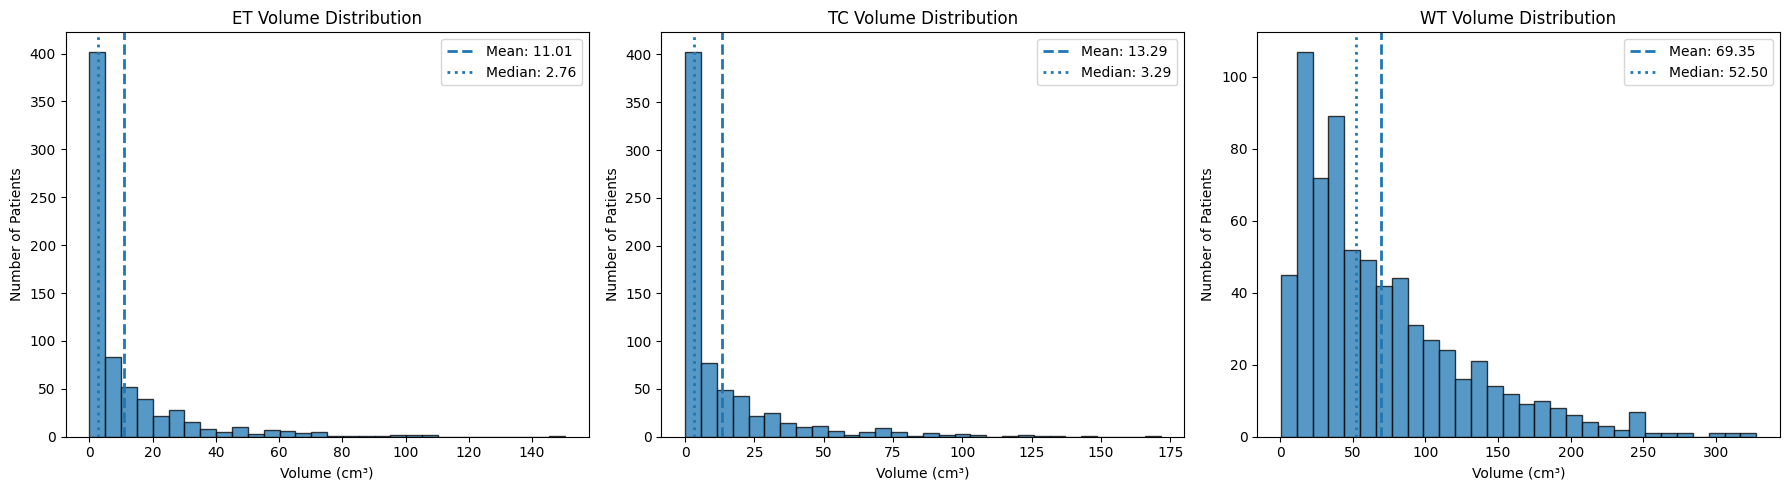

In [24]:
# Create three histogram plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

regions = ["ET_cm3", "TC_cm3", "WT_cm3"]

for ax, region in zip(axes, regions):

    # Extract volume measurements
    volumes = full_dataset_df[region]

    # Plot histogram
    ax.hist(
        volumes,
        bins=30,
        edgecolor="black",
        alpha=0.75
    )

    # Calculate mean and median
    mean_volume = volumes.mean()
    median_volume = volumes.median()

    # Mark mean and median
    ax.axvline(
        mean_volume,
        linestyle="--",
        linewidth=2,
        label=f"Mean: {mean_volume:.2f}"
    )

    ax.axvline(
        median_volume,
        linestyle=":",
        linewidth=2,
        label=f"Median: {median_volume:.2f}"
    )

    ax.set_title(f"{region.replace('_cm3', '')} Volume Distribution")
    ax.set_xlabel("Volume (cm³)")
    ax.set_ylabel("Number of Patients")
    ax.legend()

plt.tight_layout()
plt.show()

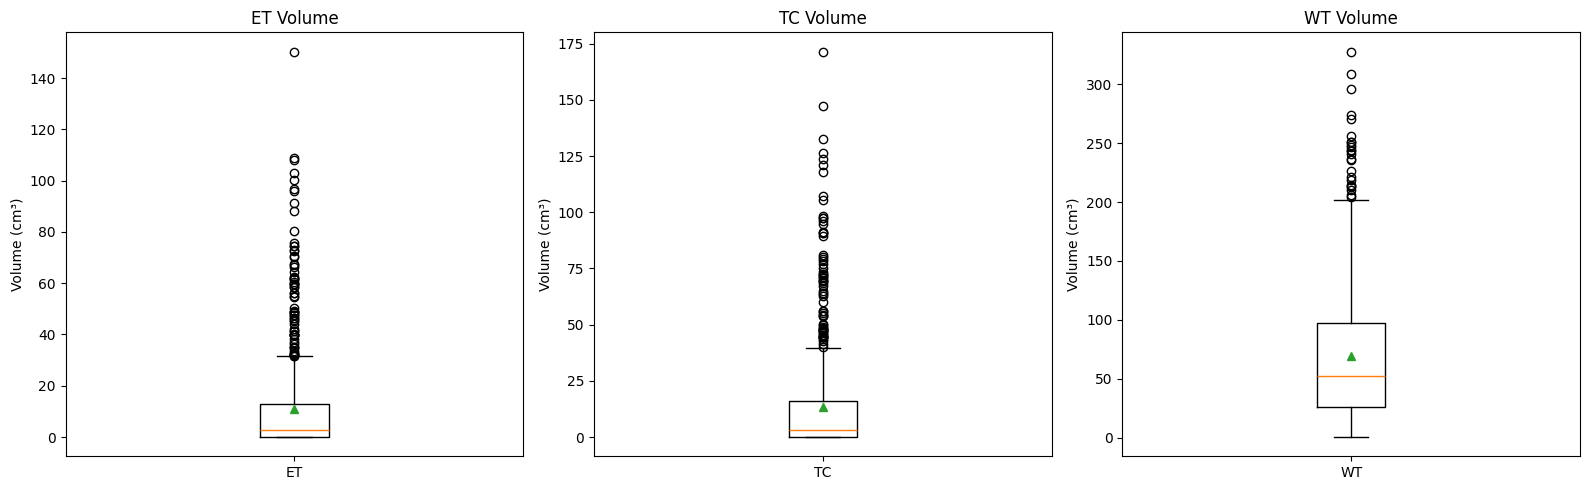

In [25]:
# Create three boxplots
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

regions = ["ET_cm3", "TC_cm3", "WT_cm3"]

for ax, region in zip(axes, regions):

    volumes = full_dataset_df[region]

    # Generate boxplot
    ax.boxplot(
        volumes,
        showmeans=True,
        showfliers=True
    )

    ax.set_title(f"{region.replace('_cm3', '')} Volume")
    ax.set_ylabel("Volume (cm³)")
    ax.set_xticks([1])
    ax.set_xticklabels([region.replace("_cm3", "")])

plt.tight_layout()
plt.show()

In [26]:
# Define tumour regions
regions = ["ET_cm3", "TC_cm3", "WT_cm3"]

# Store outlier analysis results
full_outlier_results = []

for region in regions:

    # Extract volume measurements
    volumes = full_dataset_df[region]

    # Calculate quartiles
    q1 = volumes.quantile(0.25)
    q3 = volumes.quantile(0.75)

    # Calculate interquartile range
    iqr = q3 - q1

    # Calculate outlier boundaries
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    # Identify potential outliers
    outliers = full_dataset_df[
        (full_dataset_df[region] < lower_bound) |
        (full_dataset_df[region] > upper_bound)
    ]

    # Store results
    full_outlier_results.append({
        "region": region,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": len(outliers),
        "outlier_percentage": len(outliers) / len(full_dataset_df) * 100
    })

# Convert results into a DataFrame
full_outlier_df = pd.DataFrame(full_outlier_results)

display(full_outlier_df)

,region,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage
0,ET_cm3,0.141,12.782,12.641,-18.821,31.744,69,9.857
1,TC_cm3,0.175,15.998,15.823,-23.560,39.733,67,9.571
2,WT_cm3,26.133,97.183,71.050,-80.442,203.757,24,3.429


In [27]:
# Sort patients by whole-tumour volume
top_wt_patients = (
    full_dataset_df
    .sort_values("WT_cm3", ascending=False)
    .head(10)
)

# Display their tumour-region measurements
display(
    top_wt_patients[
        ["patient_id", "ET_cm3", "TC_cm3", "WT_cm3"]
    ]
)

,patient_id,ET_cm3,TC_cm3,WT_cm3
386,BraTS-GLI-02186-103,0.702,0.702,327.711
686,BraTS-GLI-02520-101,61.573,98.490,308.285
134,BraTS-GLI-02079-101,21.323,23.589,296.143
200,BraTS-GLI-02102-101,62.247,69.274,273.503
371,BraTS-GLI-02176-103,80.346,90.875,270.649
404,BraTS-GLI-02194-103,32.869,33.936,255.997
199,BraTS-GLI-02102-100,48.654,64.161,251.239
133,BraTS-GLI-02079-100,0.256,0.377,250.920
566,BraTS-GLI-02268-101,41.413,47.836,248.277
289,BraTS-GLI-02139-101,56.002,75.308,246.741


In [28]:
# Select tumour-region volume measurements
volume_columns = ["ET_cm3", "TC_cm3", "WT_cm3"]

# Calculate Pearson correlation
pearson_corr = full_dataset_df[
    volume_columns
].corr(method="pearson")

# Calculate Spearman correlation
spearman_corr = full_dataset_df[
    volume_columns
].corr(method="spearman")

print("Pearson Correlation:")
display(pearson_corr)

print("\nSpearman Rank Correlation:")
display(spearman_corr)

Pearson Correlation:


,ET_cm3,TC_cm3,WT_cm3
ET_cm3,1.000,0.984,0.664
TC_cm3,0.984,1.000,0.666
WT_cm3,0.664,0.666,1.000



Spearman Rank Correlation:


,ET_cm3,TC_cm3,WT_cm3
ET_cm3,1.000,0.988,0.652
TC_cm3,0.988,1.000,0.649
WT_cm3,0.652,0.649,1.000


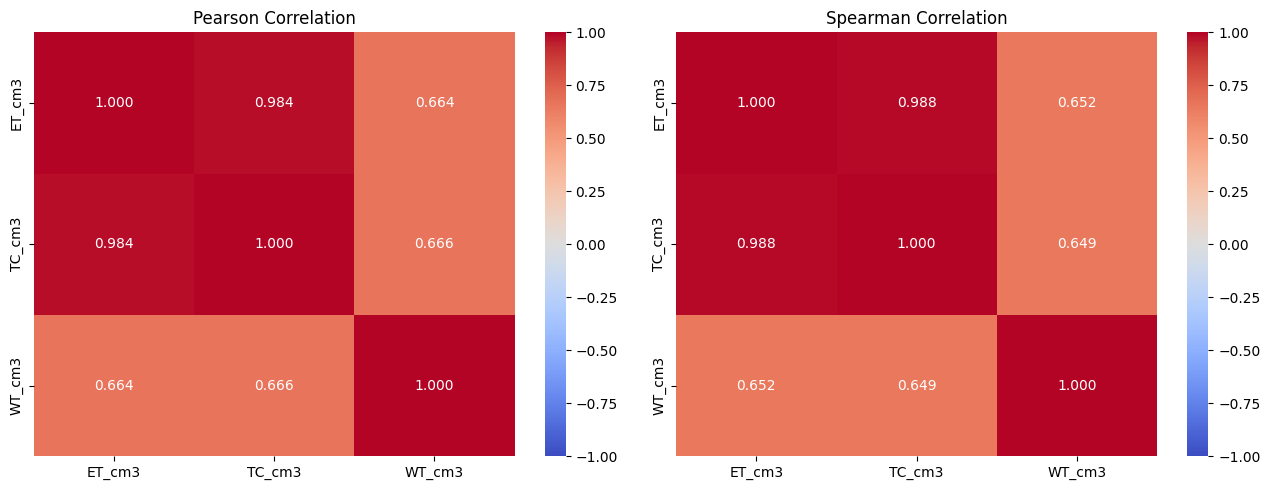

In [29]:
# Create side-by-side correlation heatmaps
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Pearson correlation heatmap
sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".3f",
    ax=axes[0]
)

axes[0].set_title("Pearson Correlation")

# Spearman correlation heatmap
sns.heatmap(
    spearman_corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".3f",
    ax=axes[1]
)

axes[1].set_title("Spearman Correlation")

plt.tight_layout()
plt.show()

In [30]:
# Calculate the relative contribution of each region to whole tumour volume

full_dataset_df["NETC_fraction"] = (
    full_dataset_df["NETC_voxels"] /
    full_dataset_df["WT_voxels"]
)

full_dataset_df["SNFH_fraction"] = (
    full_dataset_df["SNFH_voxels"] /
    full_dataset_df["WT_voxels"]
)

full_dataset_df["ET_fraction"] = (
    full_dataset_df["ET_voxels"] /
    full_dataset_df["WT_voxels"]
)

# Convert fractions into percentages
full_dataset_df["NETC_percentage"] = (
    full_dataset_df["NETC_fraction"] * 100
)

full_dataset_df["SNFH_percentage"] = (
    full_dataset_df["SNFH_fraction"] * 100
)

full_dataset_df["ET_percentage"] = (
    full_dataset_df["ET_fraction"] * 100
)

# Verify that the three components sum to 1
full_dataset_df["composition_sum"] = (
    full_dataset_df["NETC_fraction"] +
    full_dataset_df["SNFH_fraction"] +
    full_dataset_df["ET_fraction"]
)

# Check numerical consistency
print(
    "All compositions sum to 1:",
    np.allclose(full_dataset_df["composition_sum"], 1.0)
)

# Display a few patient-level results
display(
    full_dataset_df[
        [
            "patient_id",
            "NETC_percentage",
            "SNFH_percentage",
            "ET_percentage"
        ]
    ].head(10)
)

All compositions sum to 1: True


,patient_id,NETC_percentage,SNFH_percentage,ET_percentage
0,BraTS-GLI-00005-100,0.000,100.000,0.000
1,BraTS-GLI-00005-101,0.000,100.000,0.000
2,BraTS-GLI-00006-100,0.000,100.000,0.000
3,BraTS-GLI-00006-101,0.000,100.000,0.000
4,BraTS-GLI-00008-100,0.000,98.102,1.898
5,BraTS-GLI-00008-101,0.000,99.158,0.842
6,BraTS-GLI-00008-102,0.000,96.519,3.481
7,BraTS-GLI-00008-103,0.000,98.177,1.823
8,BraTS-GLI-00009-100,0.222,91.856,7.922
9,BraTS-GLI-00009-101,0.598,87.272,12.130


In [31]:
# Select tumour composition columns
composition_columns = [
    "NETC_percentage",
    "SNFH_percentage",
    "ET_percentage"
]

# Calculate descriptive statistics
composition_statistics = (
    full_dataset_df[composition_columns]
    .describe()
    .T
)

# Add median explicitly
composition_statistics["median"] = (
    full_dataset_df[composition_columns].median()
)

display(composition_statistics)

,count,mean,std,min,25%,50%,75%,max,median
NETC_percentage,700.000,2.433,6.015,0.000,0.000,0.002,2.004,70.104,0.002
SNFH_percentage,700.000,85.126,18.360,11.498,77.040,92.917,99.650,100.000,92.917
ET_percentage,700.000,12.441,15.379,0.000,0.309,6.076,19.893,88.502,6.076


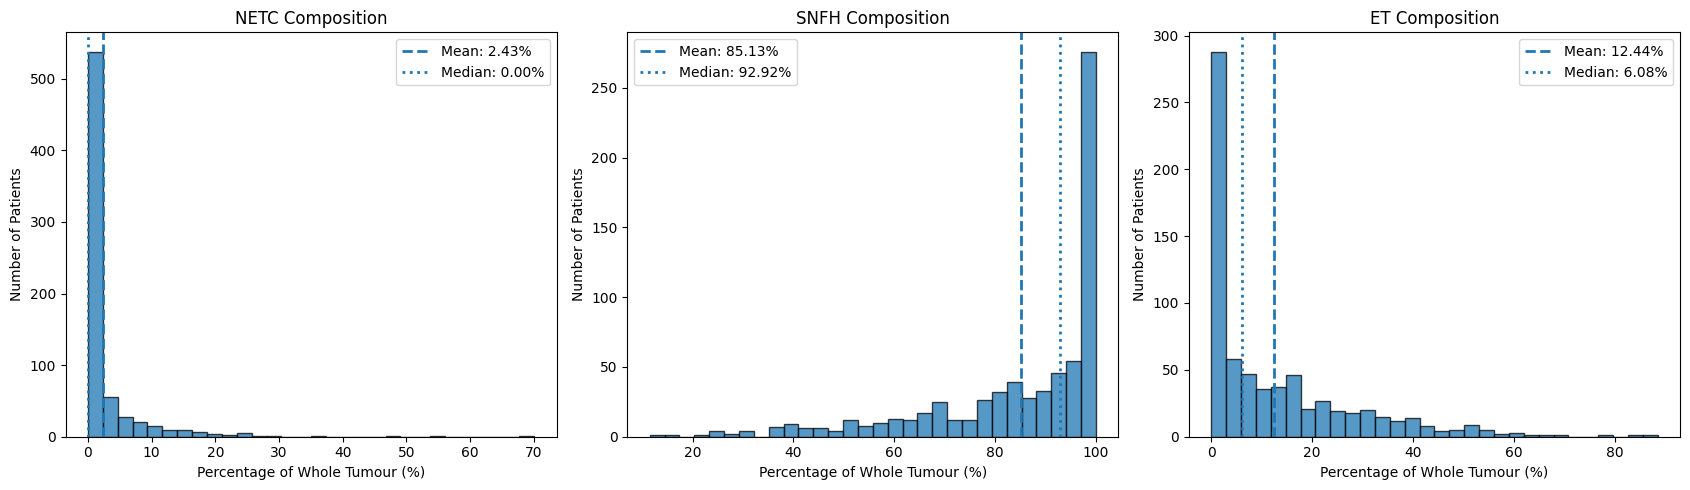

In [32]:
# Create three distribution plots
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

composition_columns = [
    "NETC_percentage",
    "SNFH_percentage",
    "ET_percentage"
]

region_names = ["NETC", "SNFH", "ET"]

for ax, column, region in zip(
    axes,
    composition_columns,
    region_names
):

    # Extract patient-level percentages
    percentages = full_dataset_df[column]

    # Plot histogram
    ax.hist(
        percentages,
        bins=30,
        edgecolor="black",
        alpha=0.75
    )

    # Calculate mean and median
    mean_value = percentages.mean()
    median_value = percentages.median()

    # Add mean and median reference lines
    ax.axvline(
        mean_value,
        linestyle="--",
        linewidth=2,
        label=f"Mean: {mean_value:.2f}%"
    )

    ax.axvline(
        median_value,
        linestyle=":",
        linewidth=2,
        label=f"Median: {median_value:.2f}%"
    )

    ax.set_title(f"{region} Composition")
    ax.set_xlabel("Percentage of Whole Tumour (%)")
    ax.set_ylabel("Number of Patients")
    ax.legend()

plt.tight_layout()
plt.show()

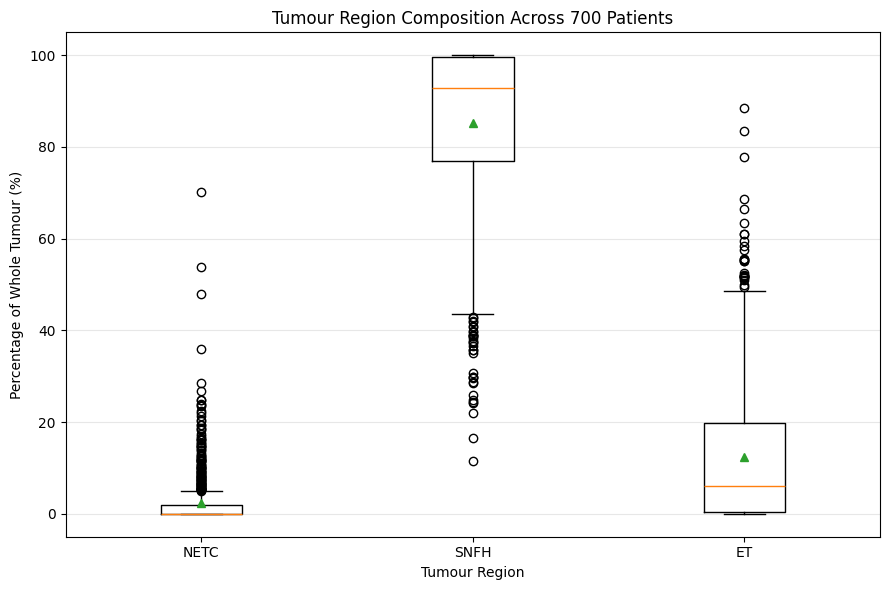

In [34]:
# Prepare composition data for plotting
composition_data = [
    full_dataset_df["NETC_percentage"],
    full_dataset_df["SNFH_percentage"],
    full_dataset_df["ET_percentage"]
]

# Create boxplot
plt.figure(figsize=(9, 6))

plt.boxplot(
    composition_data,
    tick_labels=["NETC", "SNFH", "ET"],
    showmeans=True,
    showfliers=True
)

plt.title("Tumour Region Composition Across 700 Patients")
plt.ylabel("Percentage of Whole Tumour (%)")
plt.xlabel("Tumour Region")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [35]:
# Sort patients by SNFH percentage
top_snf_patient_df = (
    full_dataset_df
    .sort_values("SNFH_percentage", ascending=False)
    .head(10)
)

# Display their tumour composition
display(
    top_snf_patient_df[
        [
            "patient_id",
            "NETC_percentage",
            "SNFH_percentage",
            "ET_percentage",
            "WT_cm3"
        ]
    ]
)

,patient_id,NETC_percentage,SNFH_percentage,ET_percentage,WT_cm3
554,BraTS-GLI-02254-101,0.000,100.000,0.000,16.582
551,BraTS-GLI-02249-101,0.000,100.000,0.000,12.355
550,BraTS-GLI-02249-100,0.000,100.000,0.000,3.582
549,BraTS-GLI-02248-104,0.000,100.000,0.000,81.609
548,BraTS-GLI-02248-103,0.000,100.000,0.000,26.890
547,BraTS-GLI-02248-102,0.000,100.000,0.000,21.623
546,BraTS-GLI-02248-101,0.000,100.000,0.000,22.209
545,BraTS-GLI-02248-100,0.000,100.000,0.000,24.245
544,BraTS-GLI-02247-104,0.000,100.000,0.000,20.090
27,BraTS-GLI-00085-101,0.000,100.000,0.000,18.245
